# Passo 1: renda e temperatura

Análise descritiva com o CSV térmico atualizado e as variáveis de renda e flags do GeoPackage.


**Objetivo:** comparar renda mediana e temperatura por setor. **Entradas:** `sector_stats_urban_v2.csv` e `sectors_income.gpkg`. **Saídas:** tabelas, gráficos e arquivos usados nas etapas seguintes. **Posição:** análise limpa e camada de visualização final do pipeline.


In [1]:
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd
from scipy.stats import spearmanr

ROOT = Path.cwd().parent
PROCESSED = ROOT / "data" / "processed"
CSV_PATH = PROCESSED / "sector_stats_urban_v2.csv"
INCOME_PATH = PROCESSED / "sectors_income.gpkg"

df = pd.read_csv(CSV_PATH)
print("Shape:", df.shape)
print("Colunas:", df.columns.tolist())
print("Valores ausentes:")
print(df.isna().sum())
print("Coluna de renda escolhida: income_median")
print("Coluna de temperatura escolhida: lst_brightness_mean_c")


Shape: (2226, 4)
Colunas: ['n_valid_bt_pixels', 'lst_brightness_mean_c', 'lst_brightness_median_c', 'sector_id']
Valores ausentes:
n_valid_bt_pixels          0
lst_brightness_mean_c      0
lst_brightness_median_c    0
sector_id                  0
dtype: int64
Coluna de renda escolhida: income_median
Coluna de temperatura escolhida: lst_brightness_mean_c


In [2]:
income = gpd.read_file(INCOME_PATH).drop(columns="geometry")
df["sector_id"] = df["sector_id"].astype("string")
income["sector_id"] = income["sector_id"].astype("string")
before_rows = len(df)
income_key_duplicates = income["sector_id"].duplicated().sum()
analysis = df.merge(income, on="sector_id", how="left", validate="one_to_one")
after_rows = len(analysis)

print("Linhas antes do merge:", before_rows)
print("Linhas depois do merge:", after_rows)
print("Setores sem renda após o merge:", analysis["income_median"].isna().sum())
print("Duplicações na chave do GeoPackage:", income_key_duplicates)
print("Não houve duplicação de linhas:", after_rows == before_rows)

filtered = analysis.loc[
    (~analysis["is_rural"])
    & analysis["income_median"].notna()
    & analysis["lst_brightness_mean_c"].notna()
].copy()
print("Setores após o filtro:", len(filtered))
# small_sector foi mantido para não excluir setores com menor área térmica observada.


Linhas antes do merge: 2226
Linhas depois do merge: 2226
Setores sem renda após o merge: 0
Duplicações na chave do GeoPackage: 0
Não houve duplicação de linhas: True
Setores após o filtro: 2226


In [3]:
# qcut cria posições relativas de renda; empates podem deixar os quintis com tamanhos diferentes.
filtered["income_quintile"] = pd.qcut(
    filtered["income_median"], 5, labels=[1, 2, 3, 4, 5]
)
filtered["income_quintile"].value_counts().sort_index()


income_quintile
1    495
2    594
3    330
4    382
5    425
Name: count, dtype: int64

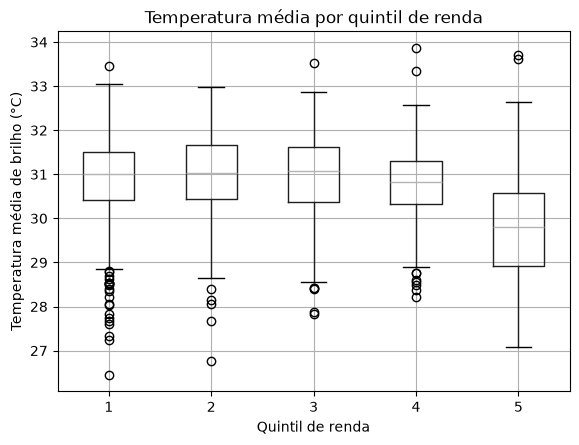

In [4]:
filtered.boxplot(column="lst_brightness_mean_c", by="income_quintile")
plt.title("Temperatura média por quintil de renda")
plt.suptitle("")
plt.xlabel("Quintil de renda")
plt.ylabel("Temperatura média de brilho (°C)")
plt.show()


In [5]:
rho, p_value = spearmanr(
    filtered["income_median"], filtered["lst_brightness_mean_c"]
)
mean_by_quintile = (
    filtered.groupby("income_quintile", observed=False)["lst_brightness_mean_c"]
    .mean()
    .rename("temperatura_media")
    .reset_index()
)
print(f"Spearman: rho = {rho:.4f}; p-valor = {p_value:.4g}")
mean_by_quintile


Spearman: rho = -0.3094; p-valor = 1.393e-50


,income_quintile,temperatura_media
0,1,30.862096
1,2,30.983932
2,3,30.958800
3,4,30.794869
4,5,29.748091


In [6]:
old_means = [38.26, 38.42, 38.34, 38.05, 36.52]
comparison = mean_by_quintile.rename(columns={"temperatura_media": "media_atual"})
comparison["media_antiga"] = old_means
comparison["rho_atual"] = rho
comparison["rho_antigo"] = -0.4087
comparison["n_atual"] = len(filtered)
comparison["n_antigo"] = 1767
comparison


,income_quintile,media_atual,media_antiga,rho_atual,rho_antigo,n_atual,n_antigo
0,1,30.862096,38.26,-0.309389,-0.4087,2226,1767
1,2,30.983932,38.42,-0.309389,-0.4087,2226,1767
2,3,30.958800,38.34,-0.309389,-0.4087,2226,1767
3,4,30.794869,38.05,-0.309389,-0.4087,2226,1767
4,5,29.748091,36.52,-0.309389,-0.4087,2226,1767


In [7]:
# O resultado descreve uma associação observada nos dados e não confirma nem refuta a hipótese.


Setores após o filtro: 2226
                 n_setores  temperatura_media  temperatura_mediana  renda_mediana
income_quintile                                                                  
1                      495          30.862096            31.002360         1300.0
2                      594          30.983932            31.036446         2000.0
3                      330          30.958800            31.068209         2424.0
4                      382          30.794869            30.815633         3000.0
5                      425          29.748091            29.803882         7000.0
Diferença Q5 - média Q1-Q4: -1.151833


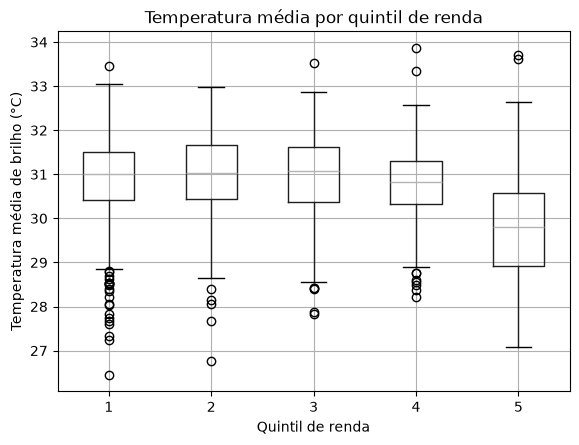

In [8]:
print("Setores após o filtro:", len(filtered))
summary = (
    filtered.groupby("income_quintile", observed=False)
    .agg(
        n_setores=("sector_id", "size"),
        temperatura_media=("lst_brightness_mean_c", "mean"),
        temperatura_mediana=("lst_brightness_mean_c", "median"),
        renda_mediana=("income_median", "median"),
    )
)
print(summary.to_string())
q1_q4_mean = summary.loc[[1, 2, 3, 4], "temperatura_media"].mean()
q5_difference = summary.loc[5, "temperatura_media"] - q1_q4_mean
print(f"Diferença Q5 - média Q1-Q4: {q5_difference:.6f}")

filtered.boxplot(column="lst_brightness_mean_c", by="income_quintile")
plt.title("Temperatura média por quintil de renda")
plt.suptitle("")
plt.xlabel("Quintil de renda")
plt.ylabel("Temperatura média de brilho (°C)")
plt.show()


## Passo 1 — conclusão

O filtro mantém setores urbanos com renda e temperatura válidas e preserva `small_sector` como informação. A comparação por quintil e Spearman descreve a associação observada, sem confirmar nem refutar a hipótese.


## Passo 2: cobertura do solo, NDVI e temperatura


O objetivo é relacionar renda com percentuais WorldCover e NDVI. A decisão é juntar as variáveis por `sector_id` e interromper se houver duplicações ou mais de 10% de ausências nas colunas novas.


In [9]:
stats_path = PROCESSED / "sector_stats_urban.csv"
stats_columns = ["sector_id", "pct_built", "pct_tree", "pct_grass", "pct_bare", "ndvi_mean"]
stats = pd.read_csv(stats_path, usecols=stats_columns)
stats["sector_id"] = stats["sector_id"].astype("string")

p2_before = len(filtered)
p2 = filtered.merge(stats, on="sector_id", how="left", validate="one_to_one")
p2_new_columns = stats_columns[1:]
p2_nan = p2[p2_new_columns].isna().sum()
p2_duplicate_ids = p2["sector_id"].duplicated().sum()
print("Linhas antes:", p2_before)
print("Linhas depois:", len(p2))
print("Duplicados de sector_id:", p2_duplicate_ids)
print("NaN nas colunas novas:")
print(p2_nan)

if p2_duplicate_ids or (p2_nan / len(p2) > 0.10).any():
    raise ValueError("Duplicação ou mais de 10% de NaN nas colunas novas; análise interrompida.")

Linhas antes: 2226
Linhas depois: 2226
Duplicados de sector_id: 0
NaN nas colunas novas:
pct_built    0
pct_tree     0
pct_grass    0
pct_bare     0
ndvi_mean    0
dtype: int64


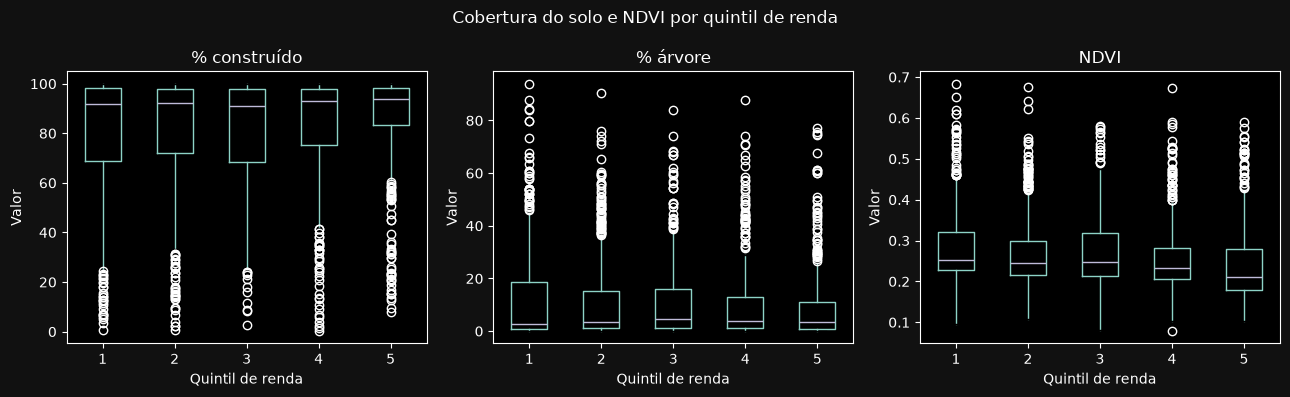

In [10]:
plt.style.use("dark_background")
fig, axes = plt.subplots(1, 3, figsize=(13, 4), facecolor="#111111")
plot_columns = [("pct_built", "% construído"), ("pct_tree", "% árvore"), ("ndvi_mean", "NDVI")]
for ax, (column, title) in zip(axes, plot_columns):
    p2.boxplot(column=column, by="income_quintile", ax=ax, grid=False)
    ax.set_title(title)
    ax.set_xlabel("Quintil de renda")
    ax.set_ylabel("Valor")
fig.suptitle("Cobertura do solo e NDVI por quintil de renda")
fig.tight_layout()
figures_path = ROOT / "outputs" / "figures"
figures_path.mkdir(parents=True, exist_ok=True)
fig.savefig(figures_path / "p2_boxplots_cobertura_ndvi.png", dpi=200, facecolor=fig.get_facecolor())
plt.show()

In [11]:
p2_means = (
    p2.groupby("income_quintile", observed=False)[["pct_built", "pct_tree", "ndvi_mean"]]
    .mean()
)
p2_means

,pct_built,pct_tree,ndvi_mean
income_quintile,,,
1,79.746999,12.098777,0.284885
2,81.201589,11.192223,0.271180
3,80.145229,11.823283,0.272462
4,81.831809,11.006729,0.259924
5,85.394401,9.468305,0.242580


In [12]:
p2["built_band"] = pd.qcut(p2["pct_built"], 3, labels=["baixa", "média", "alta"])
band_stats = (
    p2.groupby(["built_band", "income_quintile"], observed=False)["lst_brightness_mean_c"]
    .agg(media="mean", n="size")
    .reset_index()
)
band_quintile_table = band_stats.assign(
    resultado=band_stats.apply(lambda row: f"{row['media']:.3f} (n={int(row['n'])})", axis=1)
).pivot(index="built_band", columns="income_quintile", values="resultado")
band_quintile_table

income_quintile,1,2,3,4,5
built_band,,,,,
baixa,30.338 (n=185),30.470 (n=204),30.348 (n=122),30.458 (n=126),29.854 (n=105)
média,31.138 (n=139),31.158 (n=200),31.213 (n=111),30.890 (n=134),29.770 (n=158)
alta,31.205 (n=171),31.352 (n=190),31.436 (n=97),31.038 (n=122),29.658 (n=162)


## Regressões OLS

Os modelos acrescentam cobertura do solo, renda padronizada, distância aos parques e, nas extensões posteriores, altitude. Os coeficientes são associações condicionais; não representam efeitos causais.


In [13]:
# A padronização coloca renda em desvios-padrão para comparar seu coeficiente com os demais preditores.
p2["income_z"] = (p2["income_median"] - p2["income_median"].mean()) / p2["income_median"].std(ddof=0)
import statsmodels.api as sm

X = sm.add_constant(p2[["ndvi_mean", "pct_built", "income_z"]])
y = p2["lst_brightness_mean_c"]
ols = sm.OLS(y, X).fit()
ols_coefficients = pd.DataFrame({"coeficiente": ols.params, "erro_padrao": ols.bse})
print(ols_coefficients)
print(f"R²: {ols.rsquared:.6f}")

           coeficiente  erro_padrao
const        31.647137     0.211748
ndvi_mean    -3.951971     0.371293
pct_built     0.001138     0.001473
income_z     -0.483479     0.018350
R²: 0.332155


## Passos 3 e 4 — preparação e rankings

O notebook chama o script de preparação para calcular resíduos, vizinhança, distância aos parques e rankings setoriais. As operações de download/checagem ficam fora da camada visual.


In [ ]:
import subprocess

TABLES = ROOT / "outputs" / "tables"
TABLES.mkdir(parents=True, exist_ok=True)
p2.to_csv(TABLES / "analysis_df.csv", index=False)
subprocess.run(["uv", "run", "python", str(ROOT / "scripts" / "step3_4_prep.py")], check=True)


~/goiania-thermal-justice/.venv/lib/python3.13/site-packages/libpysal/weights/contiguity.py:354: UserWarning: The weights matrix is not fully connected: 
 There are 10 disconnected components.
 There are 6 islands with ids: 1295, 2214, 2215, 2216, 2222, 2225.
  W.__init__(self, neighbors, ids=ids, **kw)


('WARNING: ', 1295, ' is an island (no neighbors)')
('WARNING: ', 2214, ' is an island (no neighbors)')
('WARNING: ', 2215, ' is an island (no neighbors)')
('WARNING: ', 2216, ' is an island (no neighbors)')
('WARNING: ', 2222, ' is an island (no neighbors)')
('WARNING: ', 2225, ' is an island (no neighbors)')


~/goiania-thermal-justice/scripts/step3_4_prep.py:100: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  parks_boundary = sectors.to_crs("EPSG:4326").geometry.unary_union


OSM boundary=administrative, admin_level=10: polígonos=349; com_nome=349
OSM place=suburb: polígonos=16; com_nome=16
Polígonos descartados antes do sjoin:
                name      area_km2
      Senador Canedo    247.271003
     Abadia de Goiás    142.989202
Aparecida de Goiânia    278.900228
               Goiás 340395.662898
            Trindade    710.503959
             Goiânia    728.626515
            Goianira    214.692307


~/goiania-thermal-justice/.venv/lib/python3.13/site-packages/libpysal/weights/contiguity.py:354: UserWarning: The weights matrix is not fully connected: 
 There are 10 disconnected components.
 There are 6 islands with ids: 1295, 2214, 2215, 2216, 2222, 2225.
  W.__init__(self, neighbors, ids=ids, **kw)


## Passo 4 — extremos setoriais

As tabelas finais mostram setores extremos por temperatura e resíduo suavizados. O mapa destaca esses setores sobre a malha completa para preservar o contexto espacial.


In [ ]:
rank = pd.read_csv(ROOT / "outputs" / "tables" / "p4_setores_rank.csv")
table_columns = ["sector_id", "nome_ref", "tipo_ref", "income_median", "pct_tree"]
print("10 setores mais quentes por temp_suav")
display(rank.nlargest(10, "temp_suav")[table_columns + ["temp_suav"]])
print("10 setores mais frios por temp_suav")
display(rank.nsmallest(10, "temp_suav")[table_columns + ["temp_suav"]])
print("10 setores com maior resid_suav")
display(rank.nlargest(10, "resid_suav")[table_columns + ["resid_suav"]])
print("10 setores com menor resid_suav")
display(rank.nsmallest(10, "resid_suav")[table_columns + ["resid_suav"]])


In [ ]:
import geopandas as gpd
import matplotlib.pyplot as plt

web_sectors = gpd.read_file(ROOT / "outputs" / "web" / "sectors.geojson")
rank["sector_id"] = rank["sector_id"].astype("string")
web_sectors["sector_id"] = web_sectors["sector_id"].astype("string")
hot_ids = set(rank.nlargest(10, "temp_suav")["sector_id"])
cold_ids = set(rank.nsmallest(10, "temp_suav")["sector_id"])
hot = web_sectors[web_sectors["sector_id"].isin(hot_ids)]
cold = web_sectors[web_sectors["sector_id"].isin(cold_ids)]

plt.style.use("dark_background")
fig, ax = plt.subplots(figsize=(10, 10), facecolor="#111111")
web_sectors.plot(ax=ax, color="#555555", edgecolor="#222222", linewidth=0.1)
cold.plot(ax=ax, color="#1976d2", edgecolor="#9ecae1", linewidth=0.8, label="Mais frios")
hot.plot(ax=ax, color="#d73027", edgecolor="#fcae91", linewidth=0.8, label="Mais quentes")
ax.set_title("Setores extremos por temperatura suavizada")
ax.legend()
ax.set_axis_off()
fig.tight_layout()
fig.savefig(ROOT / "outputs" / "figures" / "p4_setores_extremos.png", dpi=200, facecolor=fig.get_facecolor())
plt.show()


## Diagnóstico de elegibilidade

A tabela separa os motivos de exclusão do ranking para tornar explícita a influência de `small_sector`, ruralidade e cobertura térmica.


In [ ]:
# Este limiar aparece apenas no diagnóstico de elegibilidade; a decisão final é mostrada explicitamente nas tabelas.
pixel_threshold = p2["n_valid_bt_pixels"].quantile(0.25)
eligibility_table = p2.assign(
    excl_small=p2["small_sector"],
    excl_rural=p2["is_rural"],
    excl_pixels=p2["n_valid_bt_pixels"] <= pixel_threshold,
).groupby("income_quintile", observed=False).agg(
    n_setores=("sector_id", "size"),
    excl_small=("excl_small", "sum"),
    excl_rural=("excl_rural", "sum"),
    excl_pixels=("excl_pixels", "sum"),
)
display(eligibility_table)
display(pd.read_csv(ROOT / "outputs" / "tables" / "p4_manchas.csv"))


## Manchas e imagens de satélite

Esta seção visualiza as manchas extremas e usa um basemap local para facilitar a leitura espacial. A figura é uma visualização, não uma nova fonte de dados analíticos.


## Visualização das manchas

As imagens mostram as manchas extremas em contexto territorial, com enquadramento local e basemap. O basemap serve à comunicação visual e não altera as métricas calculadas.


In [ ]:
import contextily as ctx
from matplotlib.patches import Patch

contexto = pd.read_csv(ROOT / "outputs" / "tables" / "p4_manchas_contexto.csv")
web_sectors = gpd.read_file(ROOT / "outputs" / "web" / "sectors.geojson")
web_sectors["sector_id"] = web_sectors["sector_id"].astype("string")

plt.style.use("dark_background")
fig, axes = plt.subplots(
    4, 3, figsize=(15, 18), facecolor="#111111", squeeze=False
)
for ax, (_, mancha) in zip(axes.flat, contexto.iterrows()):
    ids = mancha["sector_ids"].split(",")
    geometry = web_sectors[web_sectors["sector_id"].isin(ids)].to_crs("EPSG:3857")
    geometry.boundary.plot(ax=ax, color="yellow", linewidth=1.5)
    ax.set_title(
        f"{mancha['tipo']} | {mancha['temp_suav']:.1f} °C\n{mancha['dica_automatica']}"
    )
    ctx.add_basemap(ax, source=ctx.providers.Esri.WorldImagery, crs="EPSG:3857")
    ax.set_axis_off()
for ax in axes.flat[len(contexto):]:
    ax.set_visible(False)
fig.suptitle("Contexto das manchas extremas", fontsize=16)
fig.tight_layout()
fig.savefig(
    ROOT / "outputs" / "figures" / "p4_manchas_satelite.png",
    dpi=200,
    facecolor=fig.get_facecolor(),
)
plt.show()
display(contexto)


In [ ]:
import contextily as ctx
import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd
from shapely.geometry import Point

manchas = pd.read_csv(ROOT / "outputs" / "tables" / "p4_manchas.csv")
setores = gpd.read_file(ROOT / "outputs" / "web" / "sectors.geojson")
setores["sector_id"] = setores["sector_id"].astype("string")
setores_utm = setores.to_crs("EPSG:31982")
setores_3857 = setores.to_crs("EPSG:3857")
centroides = setores_utm.geometry.centroid

plt.style.use("dark_background")
n_linhas = (len(manchas) + 2) // 3
fig, axes = plt.subplots(
    n_linhas, 3, figsize=(15, 5 * n_linhas), facecolor="#111111", squeeze=False
)
for ax, (_, mancha) in zip(axes.flat, manchas.iterrows()):
    centro = gpd.GeoSeries(
        [Point(mancha["longitude"], mancha["latitude"])], crs="EPSG:4326"
    ).to_crs("EPSG:31982").iloc[0]
    distancias = centroides.distance(centro)
    ids = distancias.nsmallest(int(mancha["n_setores"])).index
    subset = setores_3857.loc[ids]
    centro_3857 = gpd.GeoSeries(
        [centro], crs="EPSG:31982"
    ).to_crs("EPSG:3857").iloc[0]
    subset.boundary.plot(ax=ax, color="yellow", linewidth=1.5)
    ax.set_xlim(centro_3857.x - 400, centro_3857.x + 400)
    ax.set_ylim(centro_3857.y - 400, centro_3857.y + 400)
    ctx.add_basemap(
        ax, source=ctx.providers.Esri.WorldImagery, crs="EPSG:3857", zoom=16
    )
    ax.set_title(
        f"{mancha['tipo']} | {mancha['temp_suav_media']:.1f} °C | "
        f"renda mediana: R$ {mancha['renda_mediana']:.0f}"
    )
    ax.set_axis_off()
for ax in axes.flat[len(manchas):]:
    ax.set_visible(False)
fig.suptitle("Imagens de satélite das manchas extremas", fontsize=16)
fig.tight_layout()
fig.savefig(
    ROOT / "outputs" / "figures" / "p4_manchas_satelite.png",
    dpi=200,
    facecolor=fig.get_facecolor(),
)
plt.show()
+

## Conclusão da etapa

O notebook reúne as comparações, diagnósticos, mapas e sensibilidades do projeto. Os resultados devem ser apresentados como associações espaciais setoriais, considerando autocorrelação, diferenças temporais e limitações de resolução.


In [32]:
# Join of land-cover fields for the additional urban-sector analysis.
stats_path = PROCESSED / "sector_stats_urban.csv"
land_columns = ["sector_id", "pct_tree", "pct_grass", "pct_bare", "pct_built"]
land = pd.read_csv(stats_path, usecols=land_columns)
land["sector_id"] = land["sector_id"].astype("string")

land_p2 = p2.drop(columns=["pct_built", "pct_tree"], errors="ignore").merge(
    land, on="sector_id", how="left", validate="one_to_one"
)
land_p2_nan = land_p2[["pct_tree", "pct_grass", "pct_bare", "pct_built"]].isna().sum()
if (land_p2_nan / len(land_p2) > 0.10).any():
    raise ValueError("More than 10% missing in one or more land-cover columns.")

land_means = (
    land_p2.groupby("income_quintile", observed=False)[
        ["pct_tree", "pct_grass", "pct_bare", "pct_built"]
    ]
    .mean()
    .round(6)
)
print("Média por quintil de renda")
print(land_means.to_string())

for column, label in [("pct_bare", "pct_bare"), ("pct_grass", "pct_grass")]:
    tercline = land_p2[["lst_brightness_mean_c", column]].dropna().copy()
    tercline["tercil"] = pd.qcut(
        tercline[column].rank(method="first"),
        3,
        labels=["1 - baixo", "2 - medio", "3 - alto"],
    )
    tercil_table = (
        tercline.groupby("tercil", observed=False)
        .agg(
            temperatura_media=("lst_brightness_mean_c", "mean"),
            n=("lst_brightness_mean_c", "size"),
        )
        .reset_index()
    )
    tercil_table["temperatura_media"] = tercil_table["temperatura_media"].round(6)
    print(f"Temperatura por tercil de {label}")
    print(tercil_table.to_string(index=False))

land_p2["renda_z"] = (
    (land_p2["income_median"] - land_p2["income_median"].mean())
    / land_p2["income_median"].std(ddof=0)
)
import statsmodels.api as sm

predictors = ["pct_tree", "pct_grass", "pct_bare", "renda_z"]
model_data = land_p2.dropna(subset=["lst_brightness_mean_c"] + predictors)
X = sm.add_constant(model_data[predictors])
y = model_data["lst_brightness_mean_c"]
ols = sm.OLS(y, X).fit()
ols_table = pd.DataFrame(
    {
        "coeficiente": ols.params[predictors],
        "erro_padrao": ols.bse[predictors],
    }
).round(6)
print("OLS: lst_brightness_mean_c ~ pct_tree + pct_grass + pct_bare + renda_z")
print(ols_table.to_string())

Média por quintil de renda
                  pct_tree  pct_grass  pct_bare  pct_built
income_quintile                                           
1                12.098777   4.013203  0.350705  79.746999
2                11.192223   3.784653  0.350991  81.201589
3                11.823283   3.767532  0.494788  80.145229
4                11.006729   3.296956  0.626284  81.831809
5                 9.468305   2.917628  0.466659  85.394401
Temperatura por tercil de pct_bare
   tercil  temperatura_media  n
1 - baixo          30.852485 742
2 - medio          30.711042 742
3 - alto           30.490619 742
Temperatura por tercil de pct_grass
   tercil  temperatura_media  n
1 - baixo          30.677437 742
2 - medio          30.807570 742
3 - alto           30.569138 742
OLS: lst_brightness_mean_c ~ pct_tree + pct_grass + pct_bare + renda_z
           coeficiente  erro_padrao
pct_tree     -0.030111     0.001174
pct_grass     0.015239     0.002658
pct_bare     -0.029765     0.007819
renda_z     